# Características no domínio da frequência — subject S1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mne

mne.set_log_level('WARNING')

ENTRADA = 'processed/S1_pre-epo.fif'     # gerado por pre-processing.ipynb
SAIDA = 'processed/S1_feat.npz'

NFFT = 1250                  # 2s completados com zeros -> passo de 0,2 Hz
N_HARM = 5                   # harmônicos do wide-band SNR
N_VIZ = 5                    # vizinhos de cada lado no narrow-band SNR

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Carregamento e espectro

In [2]:
epochs = mne.read_epochs(ENTRADA)
FS = epochs.info['sfreq']
canais = epochs.ch_names
y = epochs.events[:, 2]                                     # índice da condição (0-39)
freqs = np.array([float(k.split()[0]) for k in sorted(epochs.event_id, key=epochs.event_id.get)])
bloco = np.arange(len(y)) % 4                               # ordem: condição 0 blocos 1-4, condição 1 ...
assert np.array_equal(y, np.repeat(np.arange(40), 4))

x = epochs.copy().crop(0, 2 - 1 / FS).get_data(units='uV')  # (epochs, canais, amostras)
A = np.abs(np.fft.rfft(x, n=NFFT, axis=-1)) * 2 / x.shape[-1]
P = A ** 2
f = np.fft.rfftfreq(NFFT, 1 / FS)

print(f"filtro: {epochs.info['description']} | canais: {canais}")
print(f"sinal: {x.shape} (epochs, canais, amostras) | espectro: {A.shape} (epochs, canais, frequências)")
print(f"frequências de 0 a {f[-1]:.0f} Hz em passos de {f[1]:.1f} Hz")

filtro: band-pass 6-90 Hz | canais: ['PZ', 'PO3', 'PO5', 'PO4', 'PO6', 'POZ', 'O1', 'OZ', 'O2']
sinal: (160, 9, 500) (epochs, canais, amostras) | espectro: (160, 9, 626) (epochs, canais, frequências)
frequências de 0 a 125 Hz em passos de 0.2 Hz


- 160 epochs × 9 canais × 500 amostras (0–2 s).
- Espectro com passo de 0,2 Hz, de 0 a 125 Hz.

## 2. Funções

In [ ]:
def frequencia_mediana(S):
    # frequência onde soma acumulada do espectro S chega na metade do total
    acumulado = np.cumsum(S, axis=-1)
    return f[np.argmax(acumulado >= acumulado[..., -1:] / 2, axis=-1)]


def frequencia_media(S):
    # média das frequências ponderada pelo espectro S
    return (S * f).sum(axis=-1) / S.sum(axis=-1)


def fmd(P):  return frequencia_mediana(P)
def fmn(P):  return frequencia_media(P)
def mmdf(A): return frequencia_mediana(A)
def mmnf(A): return frequencia_media(A)
def maior(A): return A.max(axis=-1)
def media(A): return A.mean(axis=-1)


def indice(fc):
    # índice do bin de frequência mais próximo de fc
    return int(np.argmin(np.abs(f - fc)))


def narrow_snr(A, fc):
    k = indice(fc)
    vizinhos = [k + j for j in range(-N_VIZ, N_VIZ + 1) if j != 0]
    return 20 * np.log10(A[..., k] / A[..., vizinhos].mean(axis=-1))


def wide_snr(P, fc):
    sinal = P[..., [indice(h * fc) for h in range(1, N_HARM + 1)]].sum(axis=-1)
    return 10 * np.log10(sinal / (P.sum(axis=-1) - sinal))

In [4]:
candidatas = np.sort(freqs)                                    # 8,0 ... 15,8 Hz

genericas = np.stack([fmd(P), fmn(P), mmdf(A), mmnf(A), maior(A), media(A)], axis=-1)   # (epochs, canais, 6)
nomes_gen = ['FMD', 'FMN', 'MMDF', 'MMNF', 'MAX', 'MEAN']
nsnr = np.stack([narrow_snr(A, fc) for fc in candidatas], axis=-1)                     # (epochs, canais, 40)
wsnr = np.stack([wide_snr(P, fc) for fc in candidatas], axis=-1)                       # (epochs, canais, 40)

print('genéricas:', genericas.shape, '| narrow SNR:', nsnr.shape, '| wide SNR:', wsnr.shape)

genéricas: (160, 9, 6) | narrow SNR: (160, 9, 40) | wide SNR: (160, 9, 40)


- 6 características genéricas e 40 valores de cada SNR (um por frequência candidata) por canal.

## 3. Características genéricas por classe (OZ)

In [5]:
oz = canais.index('OZ')
print(f"{'classe':>8s} " + ' '.join(f'{n:>7s}' for n in nomes_gen))
for fc in [8.0, 10.0, 12.0, 14.0, 15.8]:
    sel = freqs[y] == fc
    print(f"{fc:6.1f} Hz " + ' '.join(f'{v:7.2f}' for v in genericas[sel, oz].mean(axis=0)))

  classe     FMD     FMN    MMDF    MMNF     MAX    MEAN
   8.0 Hz   17.15   25.63   30.45   36.99    7.29    0.56
  10.0 Hz   19.95   26.69   31.55   37.35    6.67    0.59
  12.0 Hz   18.95   25.66   30.20   37.04    6.02    0.54
  14.0 Hz   20.35   27.53   32.50   38.53    4.57    0.50
  15.8 Hz   21.45   28.84   34.00   38.60    5.71    0.68


- A FMN fica entre 25,6 e 28,8 Hz em todas as classes, sem acompanhar a frequência do estímulo.
- Nenhuma das 6 varia de forma ordenada com a classe.

## 4. SNR médio por classe × candidata

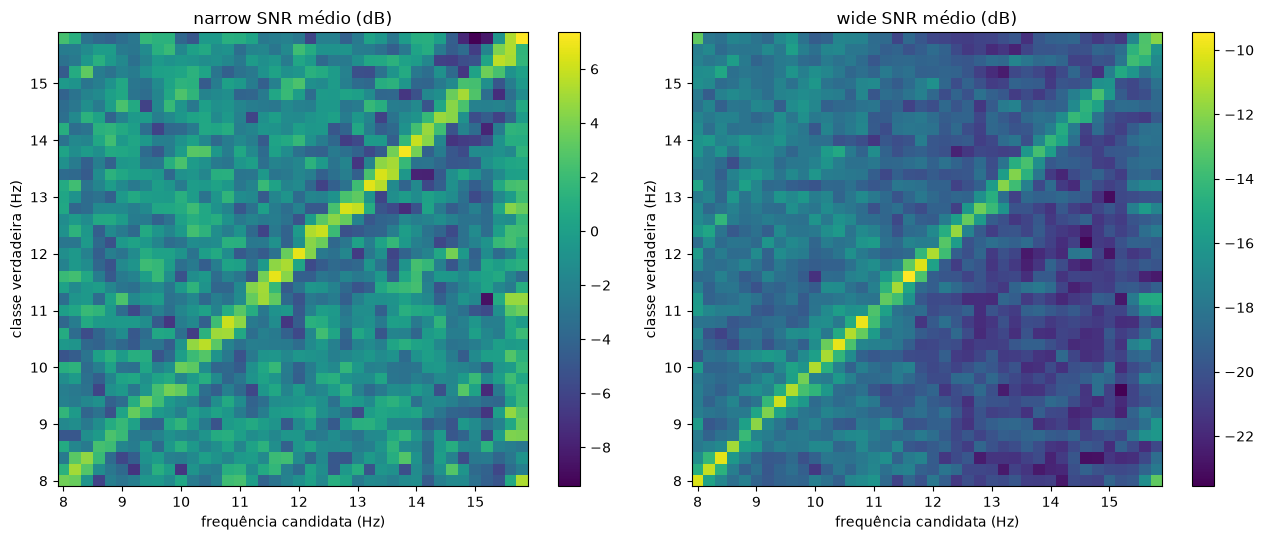

narrow SNR: maior valor acerta 62 de 160 epochs
wide SNR: maior valor acerta 122 de 160 epochs


In [ ]:
ordem = np.argsort(freqs)                       # classes verdadeiras em ordem crescente de frequência
mapa = {nome: np.array([v[y == c].mean(axis=(0, 1)) for c in ordem]) for nome, v in [('narrow SNR', nsnr), ('wide SNR', wsnr)]}

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (nome, m) in zip(axs, mapa.items()):
    im = ax.imshow(m, origin='lower', extent=[7.9, 15.9, 7.9, 15.9], cmap='viridis', aspect='auto')
    ax.set_xlabel('frequência candidata (Hz)'); ax.set_ylabel('classe verdadeira (Hz)')
    ax.set_title(f'{nome} médio (dB)'); ax.grid(False)
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

# candidata com maior SNR médio nos 9 canais é classe prevista
for nome, v in [('narrow SNR', nsnr), ('wide SNR', wsnr)]:
    prevista = candidatas[v.mean(axis=1).argmax(axis=1)]
    print(f"{nome}: maior valor acerta {np.sum(prevista == freqs[y])} de {len(y)} epochs")

- Wide SNR: diagonal estreita; a candidata de maior valor acerta 122 de 160 epochs, sem treino.
- Narrow SNR: diagonal larga e ruidosa; acerta 62 de 160.
- Os erros do wide SNR aparecem nos cantos do mapa (8 Hz × 15,8 Hz, relação de harmônico).

## 5. Vetor de características

In [7]:
def achata(v, rotulos):
    # (epochs, canais, k) -> (epochs, canais*k) e os nomes das colunas na mesma ordem
    nomes = [f'{ch}_{r}' for ch in canais for r in rotulos]
    return v.reshape(len(v), -1), nomes


X_gen, n_gen = achata(genericas, nomes_gen)
X_nsnr, n_nsnr = achata(nsnr, [f'nSNR_{fc:.1f}' for fc in candidatas])
X_wsnr, n_wsnr = achata(wsnr, [f'wSNR_{fc:.1f}' for fc in candidatas])

X = np.concatenate([X_gen, X_nsnr, X_wsnr], axis=1)
nomes = np.array(n_gen + n_nsnr + n_wsnr)
grupo = np.array(['genéricas'] * len(n_gen) + ['narrow SNR'] * len(n_nsnr) + ['wide SNR'] * len(n_wsnr))

print(f"X: {X.shape} = {len(n_gen)} genéricas + {len(n_nsnr)} narrow SNR + {len(n_wsnr)} wide SNR")
print(f"y: {y.shape}, {len(np.unique(y))} classes, {np.bincount(y)[0]} epochs por classe")
print('primeiras colunas:', list(nomes[:8]))

np.savez(SAIDA, X=X, y=y, bloco=bloco, nomes=nomes, grupo=grupo, freqs=freqs)
print('salvo em', SAIDA)

X: (160, 774) = 54 genéricas + 360 narrow SNR + 360 wide SNR
y: (160,), 40 classes, 4 epochs por classe
primeiras colunas: [np.str_('PZ_FMD'), np.str_('PZ_FMN'), np.str_('PZ_MMDF'), np.str_('PZ_MMNF'), np.str_('PZ_MAX'), np.str_('PZ_MEAN'), np.str_('PO3_FMD'), np.str_('PO3_FMN')]
salvo em processed/S1_feat.npz


- `X` com 774 colunas (54 genéricas + 360 narrow SNR + 360 wide SNR), 4 epochs por classe.

## 6. Seleção de características

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, RFE

cv = LeaveOneGroupOut()


def acuracia(*etapas, dados=X):
    # acurácia média (%) com um bloco de fora por vez
    modelo = make_pipeline(*etapas, StandardScaler(), SVC(kernel='linear'))
    return 100 * cross_val_score(modelo, dados, y, cv=cv, groups=bloco).mean()


print('sem seleção, por grupo:')
for g in ['genéricas', 'narrow SNR', 'wide SNR']:
    print(f"  {g:11s} ({np.sum(grupo == g):3d} características): {acuracia(dados=X[:, grupo == g]):5.1f}%")
print(f"  todas       ({X.shape[1]:3d} características): {acuracia():5.1f}%")

sem seleção, por grupo:
  genéricas   ( 54 características):  11.2%
  narrow SNR  (360 características):  16.2%
  wide SNR    (360 características):  68.1%
  todas       (774 características):  58.8%


- Validação com um bloco de fora por vez; acaso = 2,5%.
- Wide SNR sozinho (68,1%) supera todas juntas (58,8%); genéricas (11,2%) e narrow SNR (16,2%) ficam baixas.

### VarianceThreshold

In [9]:
variancia = X.var(axis=0)
for g in ['genéricas', 'narrow SNR', 'wide SNR']:
    v = variancia[grupo == g]
    print(f"variância {g:11s}: mínima {v.min():8.4f} | mediana {np.median(v):8.4f} | máxima {v.max():8.2f}")

print()
for limiar in [0, 0.5, 2, 8]:
    mantidas = variancia > limiar
    por_grupo = {g: int(np.sum(mantidas & (grupo == g))) for g in ['genéricas', 'narrow SNR', 'wide SNR']}
    print(f"limiar {limiar:4}: mantém {mantidas.sum():3d} {por_grupo} -> {acuracia(VarianceThreshold(limiar)):5.1f}%")

variância genéricas  : mínima   0.0002 | mediana   2.9686 | máxima    18.51
variância narrow SNR : mínima  16.2117 | mediana  30.4254 | máxima    46.85
variância wide SNR   : mínima   4.8762 | mediana   8.2384 | máxima    13.87



limiar    0: mantém 774 {'genéricas': 54, 'narrow SNR': 360, 'wide SNR': 360} ->  58.8%
limiar  0.5: mantém 762 {'genéricas': 42, 'narrow SNR': 360, 'wide SNR': 360} ->  55.6%
limiar    2: mantém 754 {'genéricas': 34, 'narrow SNR': 360, 'wide SNR': 360} ->  55.0%


limiar    8: mantém 562 {'genéricas': 10, 'narrow SNR': 360, 'wide SNR': 192} ->  46.9%


- A acurácia cai conforme o limiar sobe (58,8% → 46,9%).
- O narrow SNR tem a maior variância e é mantido; as genéricas são cortadas primeiro.

### SelectKBest

In [10]:
for k in [10, 20, 40, 80, 160, 320]:
    print(f"k = {k:3d}: {acuracia(SelectKBest(f_classif, k=k)):5.1f}%")

# quais características têm as maiores notas (ajustando em todos os dados, só para inspeção)
nota = SelectKBest(f_classif, k='all').fit(X, y).scores_
top = np.argsort(nota)[::-1][:40]
print('\n15 melhores:', ', '.join(nomes[top[:15]]))
print('das 40 melhores, por grupo:', {g: int(np.sum(grupo[top] == g)) for g in ['genéricas', 'narrow SNR', 'wide SNR']})
print('das 40 melhores, por canal:', {ch: int(np.sum([n.startswith(ch + '_') for n in nomes[top]])) for ch in canais})

k =  10:  25.0%
k =  20:  33.1%
k =  40:  49.4%


k =  80:  62.5%


k = 160:  73.8%
k = 320:  70.6%

15 melhores: POZ_wSNR_13.4, OZ_wSNR_11.8, OZ_wSNR_12.4, OZ_wSNR_14.8, POZ_wSNR_11.8, O1_wSNR_11.8, OZ_wSNR_13.4, PZ_MAX, OZ_wSNR_8.4, OZ_wSNR_15.6, O1_wSNR_15.4, OZ_wSNR_15.4, POZ_wSNR_15.6, OZ_wSNR_11.6, OZ_wSNR_14.6
das 40 melhores, por grupo: {'genéricas': 4, 'narrow SNR': 0, 'wide SNR': 36}
das 40 melhores, por canal: {'PZ': 1, 'PO3': 0, 'PO5': 0, 'PO4': 0, 'PO6': 0, 'POZ': 6, 'O1': 9, 'OZ': 20, 'O2': 4}


- Melhor resultado com k = 160: 73,8%.
- Das 40 melhores, 36 são wide SNR e nenhuma é narrow SNR; OZ, O1, POZ e O2 concentram as escolhas.

### RFE

In [11]:
rfe = lambda n: RFE(SVC(kernel='linear'), n_features_to_select=n, step=0.1)
for n in [10, 20, 40, 80, 160]:
    print(f"n = {n:3d}: {acuracia(StandardScaler(), rfe(n)):5.1f}%")   # padroniza antes: os pesos do SVM dependem da escala

escolhidas = rfe(40).fit(StandardScaler().fit_transform(X), y).support_
print('\nRFE com 40 (ajustado em todos os dados, só para inspeção):')
print('por grupo:', {g: int(np.sum(grupo[escolhidas] == g)) for g in ['genéricas', 'narrow SNR', 'wide SNR']})
print('por canal:', {ch: int(np.sum([n.startswith(ch + '_') for n in nomes[escolhidas]])) for ch in canais})

n =  10:  20.6%


n =  20:  33.8%


n =  40:  55.0%


n =  80:  61.9%


n = 160:  72.5%



RFE com 40 (ajustado em todos os dados, só para inspeção):
por grupo: {'genéricas': 5, 'narrow SNR': 1, 'wide SNR': 34}
por canal: {'PZ': 2, 'PO3': 0, 'PO5': 0, 'PO4': 1, 'PO6': 1, 'POZ': 5, 'O1': 7, 'OZ': 21, 'O2': 3}


- Melhor resultado com 160: 72,5%, próximo do SelectKBest.
- Mesma preferência por wide SNR e pelos canais OZ, O1, POZ e O2.

## 7. PCA em 2D

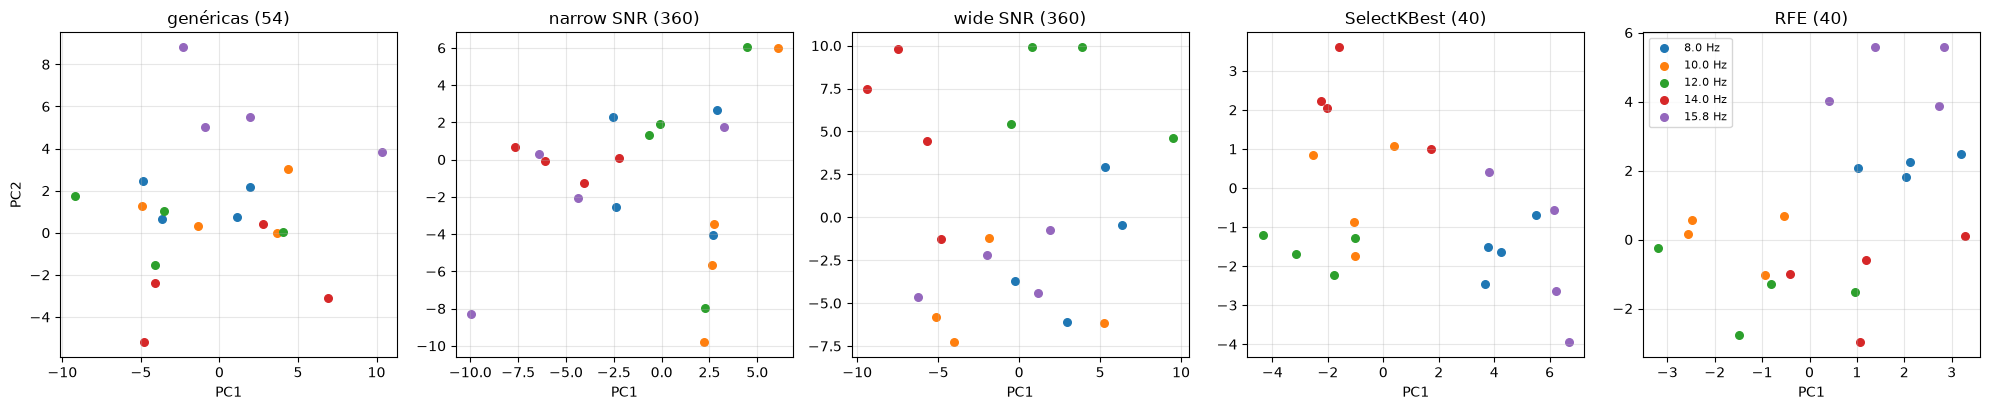

In [12]:
from sklearn.decomposition import PCA

conjuntos = {
    'genéricas': grupo == 'genéricas',
    'narrow SNR': grupo == 'narrow SNR',
    'wide SNR': grupo == 'wide SNR',
    'SelectKBest': np.isin(np.arange(X.shape[1]), top),
    'RFE': escolhidas,
}
mostrar = [8.0, 10.0, 12.0, 14.0, 15.8]

fig, axs = plt.subplots(1, 5, figsize=(20, 4.2))
for ax, (nome, cols) in zip(axs, conjuntos.items()):
    z = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X[:, cols]))
    for fc in mostrar:
        sel = freqs[y] == fc
        ax.scatter(z[sel, 0], z[sel, 1], s=30, label=f'{fc:.1f} Hz')
    ax.set_title(f'{nome} ({cols.sum()})')
    ax.set_xlabel('PC1')
axs[0].set_ylabel('PC2')
axs[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

- Genéricas e narrow SNR misturam as 5 classes.
- Wide SNR, SelectKBest e RFE formam grupos mais compactos.